<a href="https://colab.research.google.com/github/sashawrk4-pylyp/My-Python-Data-Analysis/blob/main/Restaurant_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [80]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [81]:
# Connecting Google Drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [82]:
# Changing work folder
%cd /content/drive/MyDrive/Jupyter

/content/drive/MyDrive/Jupyter


In [83]:
!find /content/drive/MyDrive/Jupyter -iname "*sqlite3*"

/content/drive/MyDrive/Jupyter/db.sqlite3


In [84]:
# Підключення та робота з базою даних
import sqlite3
conn = sqlite3.connect("db.sqlite3")
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)
print(tables)

                   name
0       sqlite_sequence
1  restaurant_orderitem
2    restaurant_product
3      restaurant_order


In [85]:
# Перевірка структури таблиць
for table in ["restaurant_order", "restaurant_orderitem", "restaurant_product"]:
    print(f"\n--- {table} ---")

    columns = pd.read_sql_query(f"PRAGMA table_info({table});", conn)
    print(columns[["name", "type"]])


--- restaurant_order ---
       name      type
0        id   INTEGER
1  datetime  datetime

--- restaurant_orderitem ---
         name     type
0          id  INTEGER
1    quantity  INTEGER
2    order_id   bigint
3  product_id   bigint

--- restaurant_product ---
    name          type
0     id       INTEGER
1  price       decimal
2   name  varchar(100)


In [86]:
# Об'єднання даних із таблиць та створення DataFrame
query = """
SELECT
    o.id AS order_id,
    o.datetime,
    oi.quantity,
    p.id AS product_id,
    p.price,
    p.name AS product_name
FROM restaurant_order AS o
JOIN restaurant_orderitem AS oi
    ON o.id = oi.order_id
JOIN restaurant_product AS p
    ON oi.product_id = p.id
"""
df = pd.read_sql_query(query, conn)
df.head()

,order_id,datetime,quantity,product_id,price,product_name
0,1,2019-08-03 20:25:00,2,6,0.80,Plain Papadum
1,1,2019-08-03 20:25:00,1,240,12.95,King Prawn Balti
2,1,2019-08-03 20:25:00,1,19,2.95,Garlic Naan
3,1,2019-08-03 20:25:00,1,36,3.95,Mushroom Rice
4,1,2019-08-03 20:25:00,1,111,8.95,Paneer Tikka Masala


In [87]:
df.shape

(74818, 6)

In [88]:
# Збереження та завантаження даних
df.to_csv("restaurant_sales.csv", index=False)
df = pd.read_csv("restaurant_sales.csv")
df.shape

(74818, 6)

In [89]:
# Розрахунок вартості товарів
df["item_price"] = df["price"] * df["quantity"]
df[["product_name", "price", "quantity", "item_price"]].head()

,product_name,price,quantity,item_price
0,Plain Papadum,0.80,2,1.60
1,King Prawn Balti,12.95,1,12.95
2,Garlic Naan,2.95,1,2.95
3,Mushroom Rice,3.95,1,3.95
4,Paneer Tikka Masala,8.95,1,8.95


## Основні показники продажів

In [90]:
# Основні показники продажів
print("Total Revenue:", df["item_price"].sum())
print("Total Quantity Sold:", df["quantity"].sum())
print("Total Orders:", df["order_id"].nunique())
print("Average Order Value:", df.groupby("order_id")["item_price"].sum().mean())

Total Revenue: 445058.45000000007
Total Quantity Sold: 93041
Total Orders: 13397
Average Order Value: 33.22075464656266


Загальний дохід ресторану становить 445 058,45, а загальна кількість проданих одиниць товарів — 93 041. За аналізований період було оформлено 13 397 замовлень із середньою вартістю 33,22. Ці показники дають загальне уявлення про обсяг продажів і фінансові результати ресторану.

## Аналіз популярності товарів

In [91]:
# Аналіз популярності товарів
top_products = (df.groupby("product_name")["quantity"].sum().sort_values(ascending=False).head(10))
print(top_products)

product_name
Plain Papadum           10648
Pilau Rice               6367
Plain Naan               4983
Garlic Naan              3318
Plain Rice               2964
Onion Bhajee             2749
Mango Chutney            2504
Chicken Tikka Masala     2473
Chapati                  1935
Mint Sauce               1840
Name: quantity, dtype: int64


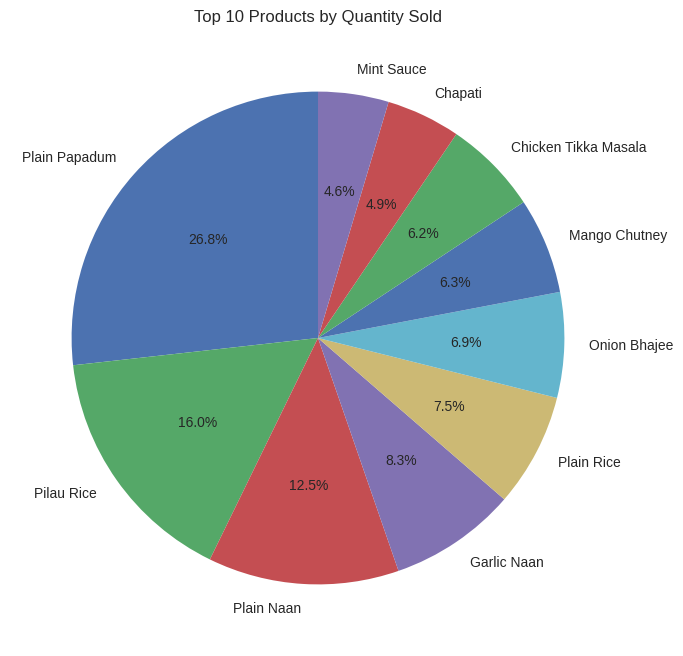

In [92]:
# Pie chart популярності товарів
plt.figure(figsize=(8, 8))
plt.style.use("seaborn-v0_8")
plt.pie(top_products, labels=top_products.index, autopct="%1.1f%%", startangle=90)
plt.title("Top 10 Products by Quantity Sold")
plt.show()

Серед 10 найпопулярніших товарів найбільшу частку проданих одиниць становить Plain Papadum — 26,8%. Далі йдуть Pilau Rice — 16% та Plain Naan — 12,5%. Інші товари мають менші частки — від 4,6% до 8,3%. Отже, Plain Papadum суттєво випереджає інші товари за кількістю продажів серед обраної десятки.

## Аналіз доходу в розрізі товарів

In [93]:
# Визначення товарів з найбільшим доходом
top_revenue = (df.groupby("product_name")["item_price"].sum().sort_values(ascending=False).head(10))
print(top_revenue)

product_name
Chicken Tikka Masala    22133.35
Pilau Rice              18782.65
Plain Naan              12955.80
Korma                   12261.50
Bombay Aloo             10894.45
Onion Bhajee            10858.55
Butter Chicken          10626.60
Garlic Naan              9788.10
Korma - Chicken          9764.45
Plain Rice               8743.80
Name: item_price, dtype: float64


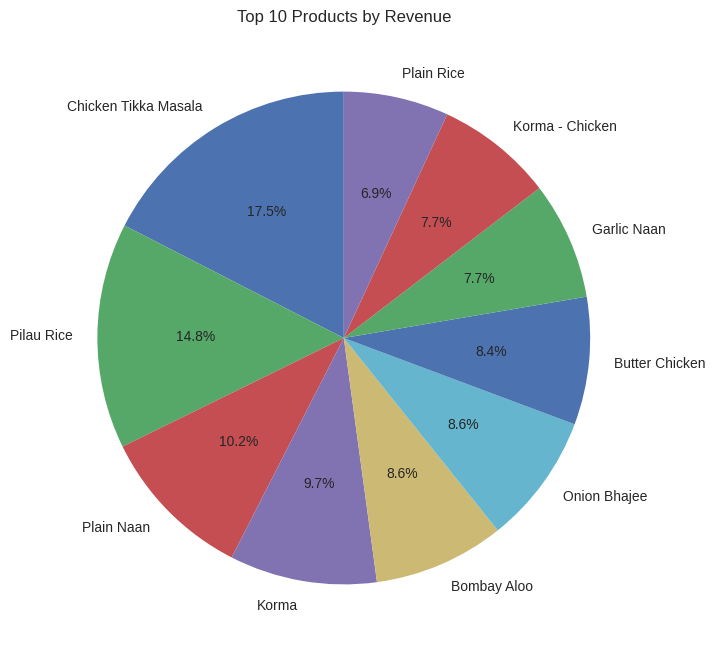

In [94]:
# Pie chart доходу від товарів
plt.figure(figsize=(8, 8))
plt.style.use("seaborn-v0_8")
plt.pie(top_revenue, labels=top_revenue.index, autopct="%1.1f%%", startangle=90)
plt.title("Top 10 Products by Revenue")
plt.show()

Серед 10 товарів із найбільшим доходом найбільшу частку становить Chicken Tikka Masala — 17,5%. Далі йдуть Pilau Rice — 14,8% та Plain Naan — 10,2%. Частки інших товарів коливаються приблизно від 6,9% до 9,7%. Отже, дохід серед топ-10 товарів розподілений відносно рівномірно, хоча Chicken Tikka Masala посідає перше місце.

## Аналіз доходу за годинами

In [95]:
df["hour"] = pd.to_datetime(df["datetime"]).dt.hour
hourly_revenue = (df.groupby("hour")["item_price"].sum())
print(hourly_revenue)

hour
0        177.95
1         54.65
2        199.25
3          8.90
4         63.45
5         57.40
6        121.60
8        447.70
9        570.60
10      1250.35
11      3807.05
12     10565.85
13      8282.65
14      3343.55
15      3781.70
16     15634.75
17     72110.20
18    132462.50
19    109045.05
20     50218.25
21     21480.30
22     11001.50
23       373.25
Name: item_price, dtype: float64


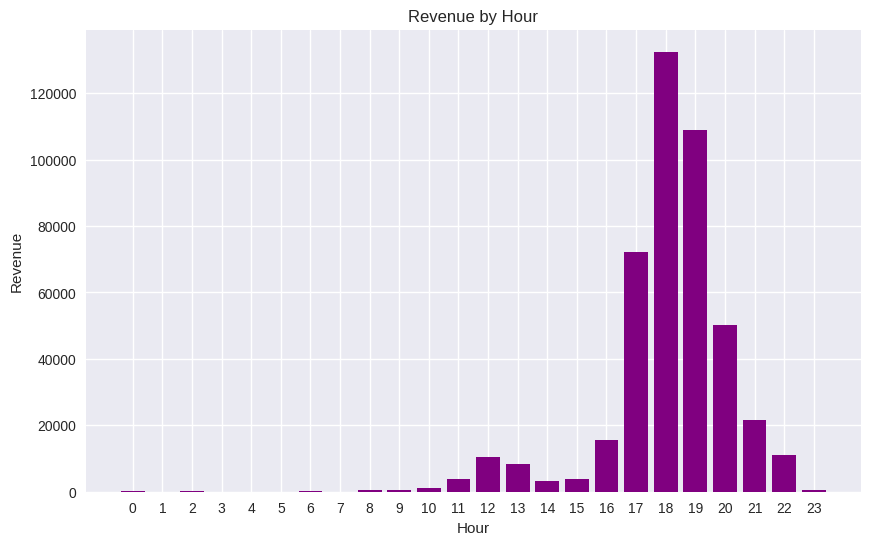

In [96]:
# Bar chart доходу за годинами
plt.figure(figsize=(10, 6))
plt.style.use("seaborn-v0_8")
plt.bar(hourly_revenue.index, hourly_revenue.values, color="purple")
plt.title("Revenue by Hour")
plt.xlabel("Hour")
plt.ylabel("Revenue")
plt.xticks(range(24))
plt.show()

Найбільший дохід ресторан отримує у вечірній час. Пікове значення припадає на 18:00 — 132 462,50, дещо менший дохід спостерігається о 19:00 — 109 045,05 та о 17:00 — 72 110,20. Після 19:00 дохід поступово знижується. У ранкові та нічні години показники значно нижчі. Отже, найактивніший період продажів — з 17:00 до 20:00.

## Аналіз доходу за місяцями

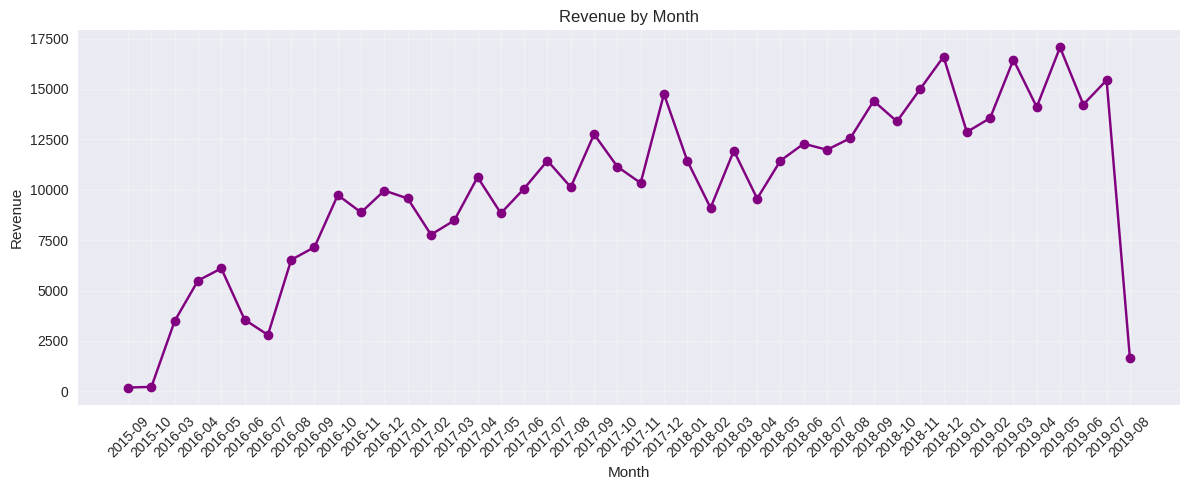

In [97]:
# Аналіз доходу за місяцями
df["month"] = pd.to_datetime(df["datetime"]).dt.to_period("M").astype(str)

monthly_revenue = df.groupby("month")["item_price"].sum()

plt.figure(figsize=(12, 5))
plt.style.use("seaborn-v0_8")
plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o", color="purple")
plt.title("Revenue by Month")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Графік відображає зміну доходу ресторану за місяцями та дає змогу визначити періоди з найвищими й найнижчими продажами. Помітні коливання доходу можуть свідчити про сезонність попиту або зміну активності клієнтів. Аналіз місячної динаміки допомагає визначити найуспішніші періоди та планувати подальші продажі.

## Аналіз доходу за днями тижня

In [98]:
df["weekday"] = pd.to_datetime(df["datetime"]).dt.day_name()
weekday_revenue = (df.groupby("weekday")["item_price"].sum())
print(weekday_revenue)

weekday
Friday       100339.15
Monday        40008.30
Saturday     112191.65
Sunday        67105.95
Thursday      46021.55
Tuesday       38145.65
Wednesday     41246.20
Name: item_price, dtype: float64


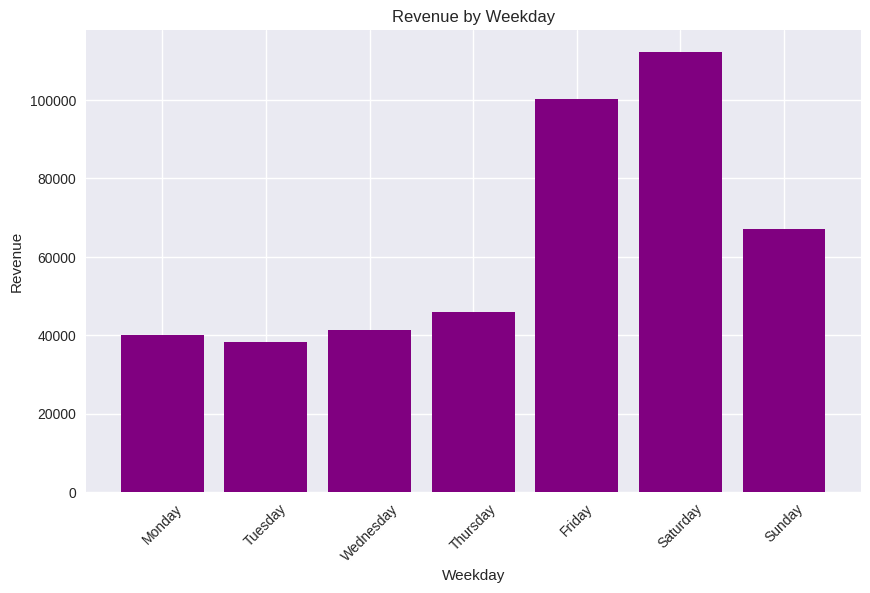

In [99]:
# Bar chart доходу за днями тижня
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday_revenue = weekday_revenue.reindex(weekday_order)

plt.figure(figsize=(10, 6))
plt.style.use("seaborn-v0_8")
plt.bar(weekday_revenue.index, weekday_revenue.values, color="purple")
plt.title("Revenue by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

Найбільший дохід ресторан отримує в суботу — 112 191,65, а найменший — у вівторок (38 145,65). Також високі показники спостерігаються в п’ятницю — 100 339,15. У неділю дохід знижується до 67 105,95. Отже, найактивнішими днями для продажів є п’ятниця та субота, що може свідчити про підвищений попит наприкінці тижня.

## Середня сума замовлення за днями тижня

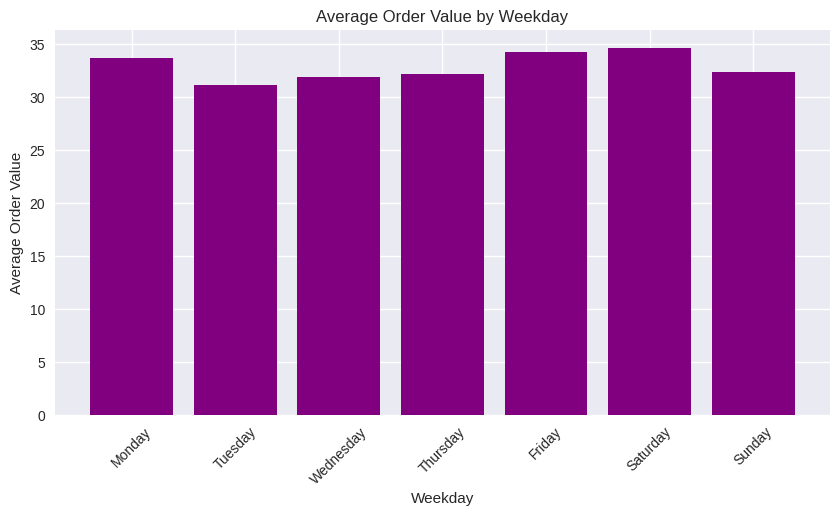

In [100]:
# Середня сума замовлення за днями тижня
order_revenue = df.groupby("order_id").agg(
    revenue=("item_price", "sum"),
    weekday=("weekday", "first"))

weekday_avg_order = order_revenue.groupby("weekday")["revenue"].mean()
weekday_avg_order = weekday_avg_order.reindex(weekday_order)

plt.figure(figsize=(10, 5))
plt.style.use("seaborn-v0_8")
plt.bar(weekday_avg_order.index, weekday_avg_order.values, color="purple")
plt.title("Average Order Value by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.show()

Графік показує середню вартість одного замовлення залежно від дня тижня. Це дає змогу визначити, у які дні клієнти в середньому витрачають більше, а в які — менше. На відміну від загального доходу, цей показник враховує середню суму окремого замовлення, а не загальний обсяг продажів за день.

## Overall Conclusion

У ході роботи було проаналізовано продажі ресторану за допомогою Python, Pandas та Matplotlib. Визначено основні показники доходу, найпопулярніші товари та залежність продажів від часу.

Загальний дохід становить 445 058,45, а кількість замовлень — 13 397. Найпопулярнішим товаром є Plain Papadum, тоді як найбільший дохід приносить Chicken Tikka Masala. Найактивніший період продажів — вечірні години, особливо 18:00, а серед днів тижня лідирують п’ятниця та субота.

Отримані результати допомагають краще зрозуміти особливості продажів і можуть бути використані для покращення роботи ресторану.